# 3. Student Distillation

Train a small Student on EchoNext using true labels and Teacher predictions. Try different training settings, select the best **validation SHD AUROC**, and plot its training history.

**You need:** the extracted EchoNext CSV and `.npy` files, plus either EchoNext-Mini or the real Teacher's saved training predictions. Teacher weights are not needed. The Student also needs Mini's architecture code, which the Mini download provides.

**Settings to edit:**

| Setting | What to do |
|---|---|
| `DATA_PATH` | Leave `None` for automatic discovery, or enter the dataset folder. Locally, the default is `data/echonext/1.1.1/`; on Kaggle, attach the dataset. |
| `TEACHER` | Leave `"mini"` to use Mini. Set `"teacher"` to use the fine-tuned Teacher's predictions. |
| `TEACHER_DIR` | In Section 3, enter the real Teacher's **training prediction folder** if using `"teacher"`. Otherwise leave `None`. |
| `small_dataset` | In the Section 2 loading call, use `True` for small subsets or `False` for the full training/validation splits. Edit `SMALL_DATASET` to change subset sizes. |
| `TRAINING_CONFIG` | Set the default training options, including batch size, learning rate, and maximum epochs. |
| `PARAM_GRID` | Set the parameter values to compare during hyperparameter tuning. These override the matching defaults. |

**Run in order.** Choose **Single Run or Hyperparameter Tuning**. Section 6 plots the tuning winner. Results are saved under `results/student/`; change `OUTPUT_ROOT` to save elsewhere. Test data is reserved for final evaluation.


## 1. Environment setup

**Run the two cells below.**

- **Kaggle:** attach the EchoNext dataset and turn Internet on. The repo and Python package are set up automatically.
- **Colab:** put the extracted dataset under `/content/echonext/`, or set `DATA_PATH` to its folder. If the files are on Google Drive, uncomment the two Drive lines first.
- **Your computer:** open this notebook from the repo. It uses `data/echonext/1.1.1/` unless you set `DATA_PATH`.

The dataset folder should contain the metadata CSV and training/validation `.npy` files.

At the end, `ENV` tells us where we are running, `BASE_DIR` is the repo folder, and `DATA_DIR` is the dataset folder.


### Repo and Dataset

In [9]:
from pathlib import Path
import os
import subprocess
import sys

REPO_URL = "https://github.com/andykimdev/compress_ECG.git"
REPO_BRANCH = "sanjay/student"
DATA_PATH = None  # Set this if your dataset is somewhere else.

# Colab only: uncomment these if your dataset is on Google Drive.
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_PATH = "/content/drive/MyDrive/echonext/1.1.1"


def download_repo(repo_dir):
    if not repo_dir.exists():
        subprocess.run(
            ["git", "clone", "--branch", REPO_BRANCH, REPO_URL, str(repo_dir)],
            check=True,
        )

    if not (repo_dir / "pyproject.toml").is_file():
        raise FileNotFoundError(f"The project files are missing from {repo_dir}")
    if not (repo_dir / "src/compress_ecg").is_dir():
        raise FileNotFoundError(f"The compress_ecg package is missing from {repo_dir}")


def find_dataset(search_dir):
    # Kaggle uploads and extracted archives can add extra folders.
    matches = list(search_dir.rglob("echonext_metadata_100k.csv"))
    matches += list(search_dir.rglob("EchoNext_metadata_100k.csv"))
    folders = []
    for metadata_file in matches:
        if metadata_file.parent not in folders:
            folders.append(metadata_file.parent)

    if len(folders) != 1:
        raise FileNotFoundError(
            f"Found {len(folders)} dataset folders under {search_dir}. "
            "Set DATA_PATH to the folder containing the metadata CSV and .npy files."
        )
    return folders[0]


In [10]:
if Path("/kaggle/working").is_dir():
    ENV = "kaggle"
    BASE_DIR = Path("/kaggle/working/compress_ECG")
    data_search_dir = Path("/kaggle/input")
elif "COLAB_RELEASE_TAG" in os.environ or "google.colab" in sys.modules:
    ENV = "colab"
    BASE_DIR = Path("/content/compress_ECG")
    data_search_dir = Path("/content/echonext")
else:
    ENV = "machine"
    BASE_DIR = Path.cwd()
    if BASE_DIR.name == "notebooks":
        BASE_DIR = BASE_DIR.parent
    if not (BASE_DIR / "pyproject.toml").is_file():
        raise FileNotFoundError("Open this notebook from the repo or its notebooks folder.")
    data_search_dir = BASE_DIR / "data/echonext"

download_repo(BASE_DIR)

if ENV != "machine":
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-e", str(BASE_DIR)],
        check=True,
    )
sys.path.insert(0, str(BASE_DIR / "src"))

if DATA_PATH is not None:
    DATA_DIR = Path(DATA_PATH).expanduser().resolve()
else:
    DATA_DIR = find_dataset(data_search_dir)

if not (DATA_DIR / "echonext_metadata_100k.csv").is_file() and not (DATA_DIR / "EchoNext_metadata_100k.csv").is_file():
    raise FileNotFoundError(f"No EchoNext metadata CSV in {DATA_DIR}")

for split in ("train", "val"):
    for filename in (f"EchoNext_{split}_waveforms.npy", f"EchoNext_{split}_tabular_features.npy"):
        if not (DATA_DIR / filename).is_file():
            raise FileNotFoundError(f"Missing dataset file: {DATA_DIR / filename}")

print("Environment:", ENV)
print("Repo:", BASE_DIR)
print("Dataset:", DATA_DIR)


Environment: machine
Repo: /Users/sanjaykumar/repos/coms6998/compress_ECG
Dataset: /Users/sanjaykumar/repos/coms6998/compress_ECG/data/echonext/1.1.1


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

from compress_ecg.baseline import load_mini, MINI_WEIGHTS_SHA256, MINI_SOURCE_SHA256
from compress_ecg.data import (
    EchoNextDataset, LABEL_COLUMNS, SHD_INDEX, METADATA_FILENAMES,
    find_metadata_file, resolve_data_dir,
)
from compress_ecg.predictions import (
    aligned_logits, basic_metrics, load_run, run_dir, sha256_file, write_run,
)
from compress_ecg.student import load_student


In [ ]:
SEED = 42
DEVICE = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
TEACHER = "mini" # OR "teacher" for the real teacher
# TEACHER_TRAIN_RUN = None  # Example: Path("/kaggle/input/private-teacher-runs/teacher/train")
# TEACHER_VAL_RUN = None


SMALL_DATASET = {
    "train": 512,
    "val": 256
}
OUTPUT_ROOT = BASE_DIR / "results" / "student"


In [ ]:
# Check the configuration here

## 2. Load Dataset

**Run the cell below.** It uses `DATA_DIR` from setup and returns `train` and `val`.

- Use `small_dataset=True` for the sizes in `SMALL_DATASET`.
- Use `small_dataset=False` for the full training and validation splits.

The same seed selects the same small subset each time.


In [17]:

def load_datasets(data_dir, small_dataset=False, seed=42):
    """Load the official training and validation splits, optionally using small subsets."""
    if small_dataset:
        train_limit = SMALL_DATASET["train"]
        val_limit = SMALL_DATASET["val"]
    else:
        train_limit = None
        val_limit = None

    train = EchoNextDataset(data_dir, "train", limit=train_limit, seed=seed)
    val = EchoNextDataset(data_dir, "val", limit=val_limit, seed=seed)

    if np.unique(val.labels[val.indices, SHD_INDEX]).size != 2:
        raise ValueError("The validation set needs both SHD classes. Increase the small validation size or use the full dataset.")

    return train, val


train, val = load_datasets(DATA_DIR, small_dataset=True, seed=SEED)
DATA_DIR = train.root  # Use the actual folder resolved by EchoNextDataset.

# Used later to check that Teacher predictions match this dataset.
metadata_path = find_metadata_file(DATA_DIR)
if metadata_path is None:
    raise FileNotFoundError(f"No EchoNext metadata CSV in {DATA_DIR}")
METADATA_HASH = sha256_file(metadata_path)

batch = next(iter(DataLoader(train, batch_size=min(8, len(train)), shuffle=False)))
print("Training ECGs:", len(train), "| Validation ECGs:", len(val))
print({key: tuple(batch[key].shape) for key in ("waveform", "tabular", "labels", "label_mask")})
print("Label order:", LABEL_COLUMNS)


Training ECGs: 512 | Validation ECGs: 256
{'waveform': (8, 12, 2500), 'tabular': (8, 7), 'labels': (8, 12), 'label_mask': (8, 12)}
Label order: ('lvef_lte_45_flag', 'lvwt_gte_13_flag', 'aortic_stenosis_moderate_or_greater_flag', 'aortic_regurgitation_moderate_or_greater_flag', 'mitral_regurgitation_moderate_or_greater_flag', 'tricuspid_regurgitation_moderate_or_greater_flag', 'pulmonary_regurgitation_moderate_or_greater_flag', 'rv_systolic_dysfunction_moderate_or_greater_flag', 'pericardial_effusion_moderate_large_flag', 'pasp_gte_45_flag', 'tr_max_gte_32_flag', 'shd_moderate_or_greater_flag')


## 3. Load Teacher Predictions

**Run the cell below.** It uses `TEACHER` from the configuration above.

- **`"mini"`:** use cached Mini training predictions if available. Otherwise, load Mini, generate predictions for `train`, and save them for next time. Different ECG selections get separate caches automatically.
- **`"teacher"`:** set `TEACHER_DIR` at the top of the cell to the real Teacher's training prediction folder. It should contain `predictions.npz`, `metadata.csv`, `manifest.json`, and `metrics.json`.

The result is `teacher_run`, ready for Student training. Teacher validation predictions are not needed here.


In [18]:
TEACHER_DIR = None  # Example: "/kaggle/input/teacher-predictions/teacher/train"
MINI_DIR = BASE_DIR / "external/IntroECG/7-EchoNext Minimodel"

import hashlib
import shutil


def load_teacher_predictions(teacher, train, teacher_dir=None):
    """Load saved training predictions, running Mini only on a cache miss."""
    if teacher not in ("mini", "teacher"):
        raise ValueError('TEACHER must be "mini" or "teacher".')

    row_ids = train.selected_metadata["row_id"].to_numpy()

    if teacher == "mini":
        # Only the selected data and Mini version affect these predictions.
        cache_settings = (
            METADATA_HASH + MINI_WEIGHTS_SHA256 + MINI_SOURCE_SHA256
            + str(row_ids.tolist())
        )
        cache_key = hashlib.sha256(cache_settings.encode()).hexdigest()[:16]
        cache_root = OUTPUT_ROOT / "mini_cache" / cache_key
        folder = run_dir("mini", "train", cache_root)
        files = ("predictions.npz", "metadata.csv", "manifest.json", "metrics.json")

        if all((folder / name).is_file() for name in files):
            print("Loading cached Mini training predictions.")
        else:
            print("Generating Mini training predictions.")
            # Discard an unfinished cache left by an interrupted prediction run.
            if folder.exists():
                shutil.rmtree(folder)

            source_file = MINI_DIR / "cradlenet/models/resnet1d_tabular.py"
            weight_file = MINI_DIR / "models/echonext_multilabel_minimodel/weights.pt"
            if not source_file.is_file() or not weight_file.is_file():
                subprocess.run(
                    ["bash", "scripts/download_weights.sh", "--mini-only"],
                    cwd=BASE_DIR, check=True,
                )

            mini = load_mini(MINI_DIR, device=DEVICE)
            write_run(
                mini, "mini", train, runs_root=cache_root,
                batch_size=64, device=DEVICE,
                weights_sha256=MINI_WEIGHTS_SHA256,
                source_sha256=MINI_SOURCE_SHA256,
            )
            del mini
            if DEVICE.startswith("cuda"):
                torch.cuda.empty_cache()
    else:
        if teacher_dir is None:
            raise ValueError('Set TEACHER_DIR when TEACHER = "teacher".')
        folder = Path(teacher_dir).expanduser().resolve()
        print("Loading real Teacher training predictions.")

    run = load_run(folder)
    if run.manifest.get("model") != teacher or run.manifest.get("split") != "train":
        raise ValueError(f"Expected {teacher} predictions for the training split in {folder}.")
    if run.manifest.get("metadata_sha256") != METADATA_HASH:
        raise ValueError("The predictions were made with different dataset metadata.")
    if not np.isin(row_ids, run.arrays["row_id"]).all():
        raise ValueError("The predictions do not cover all selected training ECGs.")
    if teacher == "mini":
        if (run.manifest.get("weights_sha256") != MINI_WEIGHTS_SHA256
                or run.manifest.get("source_sha256") != MINI_SOURCE_SHA256):
            raise ValueError("Cached predictions do not match this version of Mini.")

    return run, folder


teacher_run, teacher_run_path = load_teacher_predictions(TEACHER, train, TEACHER_DIR)
reference_run = None
print("Training predictions ready:", len(teacher_run.arrays["row_id"]))


Generating Mini training predictions.
Training predictions ready: 512


## 4. Set Up Student Trainer

### Student Config

In [25]:
### Student Training Hyperparameters
TRAINING_CONFIG = {
    # Optimization
    "batch_size": 32,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,

    # Distillation
    "temperature": 2.0,
    "hard_label_weight": 0.5,

    # Stopping
    "max_epochs": 50,
    "patience": 7,
    "min_delta": 0.001,

    # Execution
    "num_workers": 0,
}


### Single Run

In [24]:
from compress_ecg.student import build_student
from compress_ecg.distill import train_student

EXPERIMENT_NAME = "mini_small_train512_val256"

torch.manual_seed(SEED)
student = build_student(mini_dir=MINI_DIR, device=DEVICE)
checkpoint = train_student(
    student, teacher_run, train, val, OUTPUT_ROOT / EXPERIMENT_NAME,
    device=DEVICE, seed=SEED, **TRAINING_CONFIG,
)
print("Best checkpoint:", checkpoint)


Epoch 1/50 | Train loss: 2.0178 | Val loss: 0.5495 | Val AUROC: 0.5432 | Best validation AUROC: 0.5432 | Patience: 0/7
Epoch 2/50 | Train loss: 1.7638 | Val loss: 0.4495 | Val AUROC: 0.6259 | Best validation AUROC: 0.6259 | Patience: 0/7
Epoch 3/50 | Train loss: 1.6778 | Val loss: 0.3988 | Val AUROC: 0.6857 | Best validation AUROC: 0.6857 | Patience: 0/7
Epoch 4/50 | Train loss: 1.6417 | Val loss: 0.3801 | Val AUROC: 0.7118 | Best validation AUROC: 0.7118 | Patience: 0/7
Epoch 5/50 | Train loss: 1.6222 | Val loss: 0.3842 | Val AUROC: 0.7191 | Best validation AUROC: 0.7191 | Patience: 0/7
Epoch 6/50 | Train loss: 1.6080 | Val loss: 0.3689 | Val AUROC: 0.7258 | Best validation AUROC: 0.7258 | Patience: 0/7
Epoch 7/50 | Train loss: 1.5971 | Val loss: 0.3726 | Val AUROC: 0.7283 | Best validation AUROC: 0.7283 | Patience: 0/7
Epoch 8/50 | Train loss: 1.5966 | Val loss: 0.3648 | Val AUROC: 0.7329 | Best validation AUROC: 0.7329 | Patience: 0/7
Epoch 9/50 | Train loss: 1.5893 | Val loss: 0.35

### Hyperparameter Tuning

**Run this instead of the Single Run cell.** Edit `PARAM_GRID` to choose the settings to test. Every combination trains a fresh Student using the datasets and Teacher predictions already loaded.

Each experiment name includes the Teacher, dataset size, parameter values being tested, and seed. Results go under `results/student/sweep_<time>/`, with a separate folder for each experiment.

Each folder contains the best model, `training_config.json`, `history.json`, and `experiment.json`. The sweep folder contains `results.csv` and `best_experiment.json` for the run with the highest validation SHD AUROC.


In [22]:
import json
import math
import time
from datetime import datetime
from itertools import product
from compress_ecg.student import build_student
from compress_ecg.distill import train_student

PARAM_GRID = {
    "learning_rate": [1e-4, 3e-4, 1e-3],
    "temperature": [1.0, 2.0],
}


def run_experiments(training_config, param_grid):
    for name, values in param_grid.items():
        if name not in training_config or not values:
            raise ValueError(f"Check the parameter name and candidate values for {name}.")

    sweep_dir = OUTPUT_ROOT / f"sweep_{datetime.now():%Y%m%d_%H%M%S_%f}"
    dataset_size = "full" if len(train) == len(train.metadata) and len(val) == len(val.metadata) else "small"
    results = []

    for values in product(*param_grid.values()):
        tested = dict(zip(param_grid, values))
        config = {**training_config, **tested}
        parameters = "_".join(f"{name}-{value}" for name, value in tested.items())
        experiment = f"{TEACHER}_{dataset_size}_train{len(train)}_val{len(val)}_{parameters}_seed{SEED}"
        output_dir = sweep_dir / experiment
        print(f"\nTraining {experiment}")

        started_at = datetime.now().isoformat(timespec="seconds")
        started = time.perf_counter()
        torch.manual_seed(SEED)
        student = build_student(mini_dir=MINI_DIR, device=DEVICE)
        parameter_count = sum(p.numel() for p in student.parameters())
        checkpoint = train_student(
            student, teacher_run, train, val, output_dir,
            device=DEVICE, seed=SEED, **config,
        )
        elapsed = time.perf_counter() - started
        del student

        history = json.loads((output_dir / "history.json").read_text())
        best_epoch = max(history, key=lambda row: row["val_shd_auc"])
        steps_per_epoch = math.ceil(len(train) / config["batch_size"])
        details = {
            "experiment": experiment,
            "tested_parameters": tested,
            "training_config": config,
            "teacher": TEACHER,
            "teacher_predictions": str(teacher_run_path),
            "dataset": {
                "directory": str(train.root), "size": dataset_size,
                "train_records": len(train), "val_records": len(val),
                "sampling_seed": train.seed, "metadata_sha256": METADATA_HASH,
            },
            "seed": SEED, "device": DEVICE, "student_parameters": parameter_count,
            "started_at": started_at, "elapsed_seconds": elapsed,
            "epochs_completed": len(history), "steps_per_epoch": steps_per_epoch,
            "optimizer_steps": len(history) * steps_per_epoch,
            "stopped_early": len(history) < config["max_epochs"],
            "best_epoch": best_epoch["epoch"], "best_val_auc": best_epoch["val_shd_auc"],
            "checkpoint": str(checkpoint), "history": history,
        }
        (output_dir / "experiment.json").write_text(json.dumps(details, indent=2, allow_nan=False))

        results.append({
            "experiment": experiment, **tested,
            "best_val_auc": details["best_val_auc"], "best_epoch": details["best_epoch"],
            "epochs_completed": len(history), "optimizer_steps": details["optimizer_steps"],
            "elapsed_seconds": elapsed, "checkpoint": str(checkpoint),
        })
        table = pd.DataFrame(results).sort_values("best_val_auc", ascending=False)
        table.to_csv(sweep_dir / "results.csv", index=False)
        best_file = Path(table.iloc[0]["checkpoint"]).parent / "experiment.json"
        (sweep_dir / "best_experiment.json").write_text(best_file.read_text())

    return table.reset_index(drop=True)


experiment_results = run_experiments(TRAINING_CONFIG, PARAM_GRID)
display(experiment_results)
print("Best checkpoint:", experiment_results.iloc[0]["checkpoint"])



Training mini_small_train512_val256_learning_rate-0.0001_temperature-1.0_seed42
Epoch 1/50 | Train loss: 1.1609 | Val loss: 0.6639 | Val AUROC: 0.4684 | Best validation AUROC: 0.4684 | Patience: 0/7
Epoch 2/50 | Train loss: 1.0560 | Val loss: 0.6452 | Val AUROC: 0.4608 | Best validation AUROC: 0.4684 | Patience: 1/7
Epoch 3/50 | Train loss: 0.9652 | Val loss: 0.6287 | Val AUROC: 0.4724 | Best validation AUROC: 0.4724 | Patience: 0/7
Epoch 4/50 | Train loss: 0.9086 | Val loss: 0.6098 | Val AUROC: 0.4849 | Best validation AUROC: 0.4849 | Patience: 0/7
Epoch 5/50 | Train loss: 0.8751 | Val loss: 0.5882 | Val AUROC: 0.4832 | Best validation AUROC: 0.4849 | Patience: 1/7
Epoch 6/50 | Train loss: 0.8391 | Val loss: 0.5675 | Val AUROC: 0.4998 | Best validation AUROC: 0.4998 | Patience: 0/7
Epoch 7/50 | Train loss: 0.8195 | Val loss: 0.5512 | Val AUROC: 0.5195 | Best validation AUROC: 0.5195 | Patience: 0/7
Epoch 8/50 | Train loss: 0.8046 | Val loss: 0.5347 | Val AUROC: 0.5304 | Best validati

,experiment,learning_rate,temperature,best_val_auc,best_epoch,epochs_completed,optimizer_steps,elapsed_seconds,checkpoint
0,mini_small_train512_val256_learning_rate-0.001...,0.0010,2.0,0.783598,41,43,688,23.259771,/Users/sanjaykumar/repos/coms6998/compress_ECG...
1,mini_small_train512_val256_learning_rate-0.001...,0.0010,1.0,0.764461,24,31,496,17.166834,/Users/sanjaykumar/repos/coms6998/compress_ECG...
2,mini_small_train512_val256_learning_rate-0.000...,0.0003,1.0,0.758265,50,50,800,27.400624,/Users/sanjaykumar/repos/coms6998/compress_ECG...
3,mini_small_train512_val256_learning_rate-0.000...,0.0003,2.0,0.755137,50,50,800,31.367463,/Users/sanjaykumar/repos/coms6998/compress_ECG...
4,mini_small_train512_val256_learning_rate-0.000...,0.0001,2.0,0.721156,50,50,800,26.692566,/Users/sanjaykumar/repos/coms6998/compress_ECG...
5,mini_small_train512_val256_learning_rate-0.000...,0.0001,1.0,0.716249,50,50,800,27.012710,/Users/sanjaykumar/repos/coms6998/compress_ECG...


Best checkpoint: /Users/sanjaykumar/repos/coms6998/compress_ECG/results/student/sweep_20261119_221212_397212/mini_small_train512_val256_learning_rate-0.001_temperature-2.0_seed42/best_student.pt


## 6. Plot the Best Model's Training History

**Run this after hyperparameter tuning.** It plots the winning experiment's training loss, validation loss, and validation SHD AUROC. The dashed line marks the epoch saved as the best model.

The plot is also saved as `learning_curves.png` beside that model.


Best experiment: mini_small_train512_val256_learning_rate-0.001_temperature-2.0_seed42
Best model: /Users/sanjaykumar/repos/coms6998/compress_ECG/results/student/sweep_20261119_221212_397212/mini_small_train512_val256_learning_rate-0.001_temperature-2.0_seed42/best_student.pt


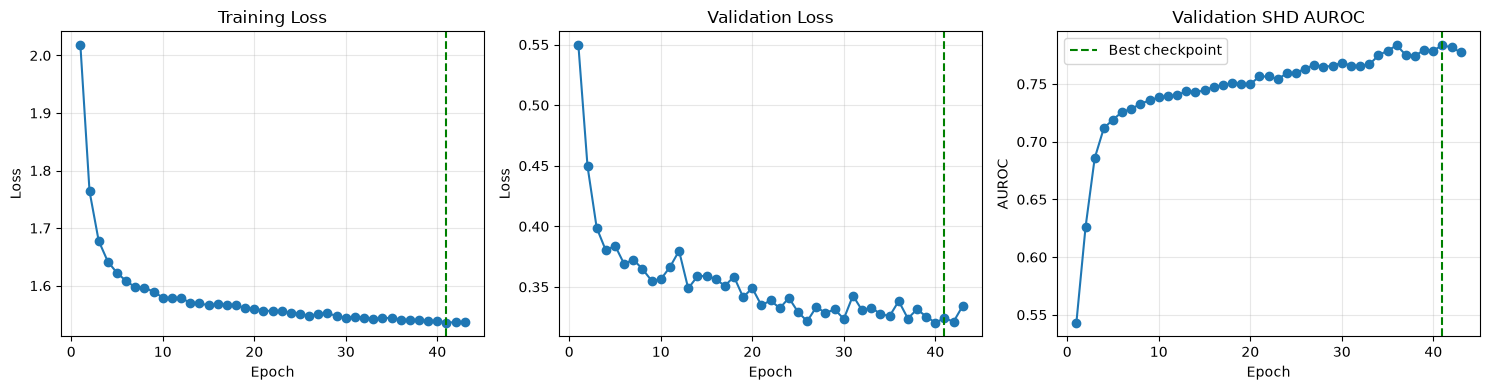

In [23]:
best_run = experiment_results.loc[experiment_results["best_val_auc"].idxmax()]
best_model_path = Path(best_run["checkpoint"])
history = pd.read_json(best_model_path.parent / "history.json")
best_epoch = history.loc[history["val_shd_auc"].idxmax(), "epoch"]

print("Best experiment:", best_run["experiment"])
print("Best model:", best_model_path)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column, title in zip(
    axes,
    ("train_loss", "val_loss", "val_shd_auc"),
    ("Training Loss", "Validation Loss", "Validation SHD AUROC"),
):
    ax.plot(history["epoch"], history[column], marker="o")
    ax.axvline(best_epoch, color="green", linestyle="--", label="Best checkpoint")
    ax.set(title=title, xlabel="Epoch", ylabel="AUROC" if column == "val_shd_auc" else "Loss")
    ax.grid(alpha=0.3)
axes[2].legend()
fig.tight_layout()
fig.savefig(best_model_path.parent / "learning_curves.png", dpi=150)
plt.show()
